# Praktikum Pertemuan 1: Eksplorasi Dataset dan Preprocessing

**Mata kuliah** Text Mining, topik Document Summarization  
**Dataset** XL-Sum Indonesia dan CNN/DailyMail  
**Keluaran** Notebook berisi seluruh langkah beserta jawaban pertanyaan diskusi

Praktikum ini membandingkan dua dataset summarization untuk melihat seberapa
*extractive* ringkasan referensinya. Hasilnya menjadi dasar memilih metode di
pertemuan berikutnya. Kalau ringkasan acuannya ternyata hampir selalu hasil salin
tempel dari dokumen, metode extractive yang sederhana sudah cukup. Kalau tidak,
extractive akan selalu kalah dan yang dibutuhkan model abstractive.

## Capaian yang dikejar

Setelah praktikum, mahasiswa mampu:

1. Memuat dataset summarization dari Hugging Face dan memahami strukturnya.
2. Menghitung statistik panjang dan rasio kompresi.
3. Melakukan segmentasi kalimat yang tahan terhadap singkatan Bahasa Indonesia.
4. Menerapkan preprocessing sesuai kebutuhan pendekatan.
5. Mengukur coverage, density, dan novel n-gram untuk mengkarakterisasi ringkasan.

## Catatan pelaksanaan

Notebook dijalankan di Jupyter lokal dengan kernel `text-mining`, yaitu virtualenv
`.venv` project ini dengan Python 3.14.5, bukan di Google Colab. Seluruh kode di sel
kode notebook ini diambil dari modul. Ada satu baris yang harus disesuaikan karena
gagal jalan di lingkungan ini, dan penyesuaiannya dijelaskan terbuka di Langkah 1.

## Langkah 0: Persiapan lingkungan

Sel di bawah adalah sel pertama modul apa adanya, dengan satu perubahan: baris
`!pip install` diberi tanda komentar. Alasannya dua. Pertama, di virtualenv project ini
`datasets`, `nltk`, dan `Sastrawi` sudah terpasang. Kedua, dan ini yang menentukan,
perintah `pip` tidak ada di PATH mesin ini, jadi kalau baris itu dijalankan selnya
langsung gagal dengan `command not found` dan notebook berhenti di sel pertama. Hapus
tanda komentar kalau notebook ini dipindah ke Google Colab seperti yang diasumsikan
modul.

Satu hal lain yang perlu diantisipasi: `nltk.download` di mesin ini gagal dengan pesan
`CERTIFICATE_VERIFY_FAILED` karena Python tidak membaca sertifikat sistem macOS. Pesan
itu akan muncul di keluaran sel dan **boleh diabaikan**, karena berkas `punkt_tab` sudah
pernah terunduh dan tersimpan di `~/nltk_data`. Buktinya `sent_tokenize` tetap bekerja
di seluruh notebook ini. Kalau di mesin lain berkasnya belum ada, jalankan sekali di
terminal:

```bash
python -c "import ssl, certifi, nltk; ssl._create_default_https_context = lambda *a, **k: ssl.create_default_context(cafile=certifi.where()); nltk.download('punkt_tab')"
```

Modul juga mencatat, kalau muncul error `punkt_tab` pada NLTK versi lama, ganti dengan
`nltk.download("punkt")`.

In [1]:
# !pip install -q datasets nltk Sastrawi

import re
import nltk
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from nltk.tokenize import sent_tokenize

nltk.download("punkt_tab", quiet=True)
pd.set_option("display.max_colwidth", 200)

[nltk_data] Error loading punkt_tab: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1081)>


## Langkah 1: Memuat dataset

Yang dipakai 2.000 sampel dari split validasi agar proses cepat. XL-Sum Indonesia
berisi berita BBC Indonesia dengan ringkasan satu kalimat. CNN/DailyMail berisi
berita berbahasa Inggris dengan ringkasan berupa beberapa poin highlight.

### Satu baris yang harus disesuaikan

Baris dari modul, `load_dataset("csebuetnlp/xlsum", "indonesian", split="validation")`,
gagal di lingkungan ini dengan pesan:

```
RuntimeError: Dataset scripts are no longer supported, but found xlsum.py
```

Penyebabnya repo `csebuetnlp/xlsum` masih memakai loading script Python, sedangkan
library `datasets` versi 3 ke atas sudah membuang dukungan script karena alasan
keamanan. Di sini terpasang versi 5.1.0, jadi scriptnya ditolak. Masalahnya bukan
di kode modul, tapi di versi library.

Supaya perubahannya sekecil mungkin, baris modul tetap ditulis apa adanya dan cuma
dibungkus `try`. Kalau dia berhasil, itu yang dipakai. Kalau dia gagal, barulah dataset
yang sama diambil dari branch `refs/convert/parquet`, yaitu salinan Parquet yang dibuat
otomatis oleh Hugging Face untuk setiap dataset, satu folder per bahasa. Datasetnya
identik, cuma jalur bacanya berbeda.

`except` ditulis luas, menangkap `Exception`, bukan `RuntimeError` saja. Ini bukan
kemalasan, tapi hasil percobaan: jenis errornya ternyata berbeda tergantung situasi.
Kalau Hub terjangkau, yang keluar `RuntimeError: Dataset scripts are no longer
supported`. Kalau panggilan ke Hub gagal, misalnya karena koneksi atau pembatasan laju
permintaan tanpa token, `datasets` diam diam beralih ke cache lokal lalu melempar
`ValueError: Couldn't find cache for csebuetnlp/xlsum for config 'indonesian'`. Dua
duanya harus jatuh ke jalur Parquet, jadi `except`-nya tidak boleh menyebut satu tipe
saja. Nama tipe errornya dicetak supaya tetap kelihatan mana yang sedang terjadi.

Modul menyarankan pindah ke IndoSum kalau XL-Sum error, tapi `SEACrowd/indosum`
juga berbasis loading script sehingga kena masalah yang sama. Jadi dataset tetap
XL-Sum Indonesia dan CNN/DailyMail sesuai modul.

In [2]:
N = 2000

try:
    xlsum = load_dataset("csebuetnlp/xlsum", "indonesian", split="validation")
except Exception as e:
    # datasets 5.x menolak loading script, dataset yang sama dibaca dari branch Parquet
    print("Cara modul gagal, beralih ke branch Parquet.")
    print(" ", type(e).__name__, str(e).splitlines()[0])
    xlsum = load_dataset("csebuetnlp/xlsum", data_dir="indonesian",
                         split="validation", revision="refs/convert/parquet")
df_id = xlsum.shuffle(seed=42).select(range(N)).to_pandas()[["title", "text", "summary"]]

cnndm = load_dataset("abisee/cnn_dailymail", "3.0.0", split="validation")
df_en = cnndm.shuffle(seed=42).select(range(N)).to_pandas()
df_en = df_en.rename(columns={"article": "text", "highlights": "summary"})[["text", "summary"]]

print(df_id.shape, df_en.shape)
df_id.head(3)

Using the latest cached version of the dataset since csebuetnlp/xlsum couldn't be found on the Hugging Face Hub


Cara modul gagal, beralih ke branch Parquet.
  ValueError Couldn't find cache for csebuetnlp/xlsum for config 'indonesian'


(2000, 3) (2000, 2)


,title,text,summary
0,Biaya pesta ultah anak kian menggila,"Perusahaan penyelenggara ulang tahun anak-anak mengatakan, biaya yang dikeluarkan untuk pesta sangat mahal Namun, permintaan semacam itu benar-benar diajukan salah seorang klien perusahaan event o...",Mengundang para tokoh Disney untuk menari di gelanggang es yang Anda bangun di rumah mungkin sedikit berlebihan untuk merayakan pesta ulang tahun bocah balita.
1,Perundingan Israel-Palestina kembali buntu,Israel Palestina kembali memulai pembicaraan damai dengan AS sebagai penengah. Pembicaraan damai itu dimulai pada Juli lalu setelah terhenti sekitar tiga tahun. Putaran terakhir dilakukan pada pek...,Tenggat pembicaraan damai antara Israel dan Palestina yang ditetapkan Amerika Serikat telah berakhir tanpa kesepakatan.
2,Pembunuhan WNI yang gemparkan Inggris,"Ayah Sumarti Ningsih diberitakan menuntut pembunuh putrinya dieksekusi. Dua perempuan Indonesia dibunuh secara sadis di distrik Wan Chai, Hong Kong. Pelakunya diduga adalah seorang bankir asal Ing...","Di atas kereta menuju tempat kerja, dua penumpang asyik mengobrol soal peristiwa yang menjadi salah satu berita utama harian gratis terbitan London, Metro."


### Cek pemahaman

Modul meminta tiga pasangan dokumen dan ringkasan dari masing masing dataset dibaca
dulu, lalu kesan awalnya dicatat, supaya nanti kelihatan apakah tebakan manusia cocok
dengan angka. Dokumennya dipotong 500 karakter pertama karena yang mau dilihat cuma
kalimat pembukanya, bagian yang paling mungkin disalin ke ringkasan.

In [3]:
# Tiga pasangan pertama tiap dataset. Dokumen dipotong 500 karakter karena yang
# dicari cuma kalimat pembukanya, bagian yang paling mungkin disalin ke ringkasan.
for nama, df in [("XL-SUM INDONESIA", df_id), ("CNN/DAILYMAIL", df_en)]:
    print(f"\n{'=' * 78}\n{nama}\n{'=' * 78}")
    for i in range(3):
        print(f"\n[{i}] RINGKASAN ACUAN:")
        print("   ", df.loc[i, "summary"].replace("\n", " | ")[:400])
        print(f"[{i}] AWAL DOKUMEN:")
        print("   ", df.loc[i, "text"][:500], "...")


XL-SUM INDONESIA

[0] RINGKASAN ACUAN:
    Mengundang para tokoh Disney untuk menari di gelanggang es yang Anda bangun di rumah mungkin sedikit berlebihan untuk merayakan pesta ulang tahun bocah balita.
[0] AWAL DOKUMEN:
    Perusahaan penyelenggara ulang tahun anak-anak mengatakan, biaya yang dikeluarkan untuk pesta sangat mahal Namun, permintaan semacam itu benar-benar diajukan salah seorang klien perusahaan event organizer bernama Quintessentially Events & Weddings. Pada sebuah musim dingin, perusahaan ini menciptakan tema luar ruangan di dalam ruangan untuk pesta ulang tahun anak-anak. Dengan tema itu, perusahaan tersebut menanam rumput dalam ruangan, lengkap dengan pohon-pohon, bunga, ayunan dan peluncur. Menur ...

[1] RINGKASAN ACUAN:
    Tenggat pembicaraan damai antara Israel dan Palestina yang ditetapkan Amerika Serikat telah berakhir tanpa kesepakatan.
[1] AWAL DOKUMEN:
    Israel Palestina kembali memulai pembicaraan damai dengan AS sebagai penengah. Pembicaraan damai itu 

### Kesan awal sebelum menghitung

Dari enam pasangan di atas, CNN/DailyMail yang terasa lebih banyak menyalin. Poin
poin highlightnya banyak memakai frasa yang sama persis dengan isi artikel, cuma
dipotong dan dirapikan. Ringkasan XL-Sum kelihatan ditulis ulang: kalimatnya
merangkum inti berita dengan pilihan kata sendiri, dan sering memadatkan informasi
dari beberapa kalimat berbeda.

Ada alasan struktural di belakang itu. Ringkasan XL-Sum diambil dari paragraf pembuka
artikel BBC, lalu paragraf itu dibuang dari kolom `text`. Jadi secara definisi
kalimat ringkasannya tidak ada di dalam dokumen. Tebakan ini diuji dengan angka di
Langkah 5.

## Langkah 2: EDA panjang dan rasio kompresi

Rasio kompresi dihitung sebagai jumlah kata dokumen dibagi jumlah kata ringkasan.
Semakin besar nilainya, semakin padat ringkasan dan semakin sulit tugasnya. Rasio 12
berarti model harus membuang sekitar 92 persen isi dokumen tapi tetap mempertahankan
intinya.

Tokenisasi katanya sengaja kasar, cuma `\w+` dengan regex. Untuk menghitung panjang
dan rasio, tokenizer kasar sudah cukup dan hasilnya konsisten untuk kedua bahasa.
Pembagi dijaga minimal 1 dengan `clip(lower=1)` supaya ringkasan kosong tidak
menghasilkan pembagian nol.

Yang dipakai median, bukan rata rata, karena panjang artikel berita punya ekor kanan
yang panjang: beberapa artikel sangat panjang akan menarik rata rata ke atas dan
membuat angkanya tidak mewakili artikel tipikal.

In [4]:
def tok(t):
    return re.findall(r"\w+", t.lower())

def profil(df):
    out = pd.DataFrame({
        "kata_dok": df["text"].map(lambda t: len(tok(t))),
        "kata_ringkasan": df["summary"].map(lambda t: len(tok(t))),
        "kalimat_dok": df["text"].map(lambda t: len(sent_tokenize(t))),
        "kalimat_ringkasan": df["summary"].map(lambda t: len(sent_tokenize(t))),
    })
    out["kompresi"] = out["kata_dok"] / out["kata_ringkasan"].clip(lower=1)
    return out

p_id, p_en = profil(df_id), profil(df_en)
pd.concat({"XL-Sum (id)": p_id.median(), "CNN/DM (en)": p_en.median()}, axis=1).round(1)

,XL-Sum (id),CNN/DM (en)
kata_dok,257.0,610.5
kata_ringkasan,21.0,52.0
kalimat_dok,14.0,28.0
kalimat_ringkasan,1.0,4.0
kompresi,12.5,11.2


### Catatan hasil Langkah 2

Modul meminta empat angka dicatat untuk kedua dataset.

| Median | XL-Sum (id) | CNN/DM (en) |
|:-|-:|-:|
| panjang dokumen (kata) | 257,0 | 610,5 |
| panjang ringkasan (kata) | 21,0 | 52,0 |
| jumlah kalimat dokumen | 14,0 | 28,0 |
| jumlah kalimat ringkasan | 1,0 | 4,0 |
| rasio kompresi | 12,5 | 11,2 |

Tiga hal yang kelihatan:

- Dokumen CNN/DailyMail sekitar 2,4 kali lebih panjang daripada XL-Sum.
- Ringkasan CNN/DailyMail juga 2,5 kali lebih panjang, dan terdiri dari 4 kalimat
  sementara XL-Sum cuma 1 kalimat.
- Karena dokumen dan ringkasan ikut membesar bersamaan, **rasio kompresinya justru
  mirip**, 11,2 berbanding 12,5.

Poin ketiga yang penting. Rasio kompresi yang mirip berarti tingkat kesulitan dua
dataset ini tidak bisa dibedakan dari rasio kompresi saja. Kalau dua dataset ini
berbeda karakter, bedanya ada di tempat lain, dan itu yang dicari di Langkah 5.

Beda jumlah kalimat ringkasan punya konsekuensi praktis: metode extractive yang
mengambil 3 kalimat otomatis kepanjangan untuk XL-Sum yang ringkasan acuannya cuma
1 kalimat.

Histogram berikut membandingkan sebaran panjang dokumen dan panjang ringkasan dalam
satu bidang, supaya jarak antara keduanya kelihatan. Panjang dokumen dipotong di
1.500 kata dengan `clip(upper=1500)` supaya artikel ekstrem tidak menarik sumbu x
sampai ribuan dan membuat batang lain gepeng. Dokumen yang kena potong menumpuk di
batang paling kanan, jadi batang itu harus dibaca sebagai 1.500 kata atau lebih.
Pada XL-Sum tidak ada dokumen sepanjang itu, sedangkan pada CNN/DailyMail ada 67
dokumen atau 3,4 persen.

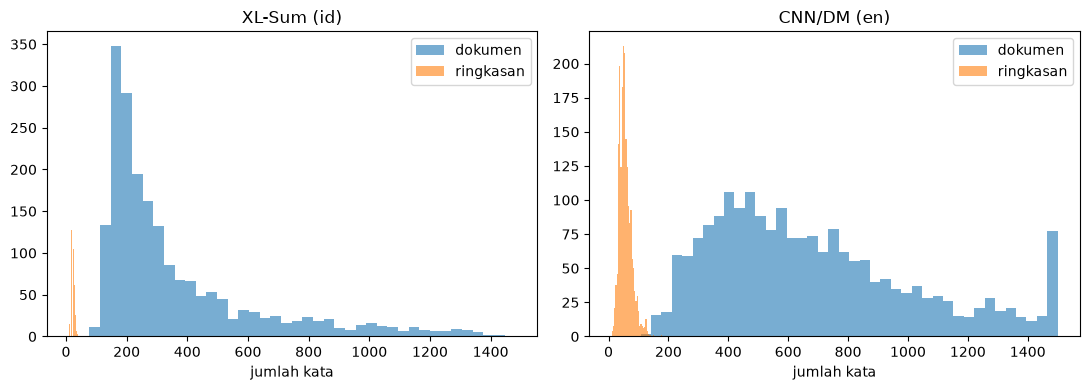

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nama, p) in zip(axes, [("XL-Sum (id)", p_id), ("CNN/DM (en)", p_en)]):
    ax.hist(p["kata_dok"].clip(upper=1500), bins=40, alpha=0.6, label="dokumen")
    ax.hist(p["kata_ringkasan"], bins=40, alpha=0.6, label="ringkasan")
    ax.set_title(nama)
    ax.set_xlabel("jumlah kata")
    ax.legend()
plt.tight_layout()
plt.show()

Dua histogramnya berbentuk sama: satu gundukan ringkasan yang rapat di dekat nol, dan
satu sebaran dokumen yang lebar dan miring ke kanan. Yang berbeda cuma skalanya.
Bentuk yang mirip ini konsisten dengan rasio kompresi yang mirip tadi, dan sekali
lagi menunjukkan bahwa pembeda dua dataset ini bukan soal panjang.

## Langkah 3: Segmentasi kalimat

Metode extractive bekerja pada level kalimat, jadi kualitas pemotong kalimat
menentukan batas atas kualitas ringkasannya. Kalau satu kalimat terpotong jadi tiga
potongan, metode secanggih apa pun akan memilih potongan yang tidak utuh.

Teks uji dari modul dirancang khusus untuk menjebak pemotong kalimat. Isinya empat
kalimat, dengan banyak titik yang bukan akhir kalimat: gelar `Dr.`, singkatan `Univ.`,
angka desimal `2.5%`, pemisah ribuan `Rp1.500`, singkatan `tsb.` dan `pk.`, jam
`10.00`, serta URL `www.bps.go.id` yang berisi dua titik di tengah.

In [6]:
teks = ("Dr. Siti dari Univ. Indonesia menyebut harga naik 2.5% menjadi Rp1.500/kg. "
        "Data tsb. dirilis pk. 10.00 WIB. Apakah tren ini berlanjut? Lihat www.bps.go.id.")

# (a) Naif: potong setiap titik
naif = [s.strip() for s in teks.split(".") if s.strip()]
print("Naif:", len(naif))

# (b) NLTK bawaan (dilatih pada bahasa Inggris)
print("NLTK:", len(sent_tokenize(teks)))
for s in sent_tokenize(teks):
    print("  -", s)

Naif: 13
NLTK: 7
  - Dr. Siti dari Univ.
  - Indonesia menyebut harga naik 2.5% menjadi Rp1.500/kg.
  - Data tsb.
  - dirilis pk.
  - 10.00 WIB.
  - Apakah tren ini berlanjut?
  - Lihat www.bps.go.id.


### Kenapa dua cara itu gagal

Cara naif menghasilkan 13 potongan dari 4 kalimat. Setiap titik dianggap batas
kalimat, sehingga `2.5%` jadi dua potongan dan URL jadi empat.

NLTK jauh lebih baik, 7 kalimat, karena model Punkt sudah paham angka desimal dan
pemisah ribuan. Tapi tiga pemotongannya masih salah, dan ketiganya di singkatan
Bahasa Indonesia: `Univ.`, `tsb.`, dan `pk.`. Masuk akal, karena model Punkt bawaan
NLTK dilatih pada korpus berbahasa Inggris dan daftar singkatan yang dihafalnya juga
singkatan Inggris.

Perbaikannya dua langkah seperti di modul. Pertama, daftar singkatan Bahasa Indonesia
diberikan langsung ke `PunktParameters.abbrev_types`, jadi Punkt tahu titik setelah
token itu bukan akhir kalimat. Perhatikan daftarnya ditulis tanpa titik dan huruf
kecil, karena begitu format yang diharapkan Punkt. Kedua, URL diganti token `<URL>`
sebelum dipotong, supaya titik di dalam alamat tidak pernah dilihat pemotong kalimat.

In [7]:
from nltk.tokenize.punkt import PunktSentenceTokenizer, PunktParameters

SINGKATAN = {"dr", "drs", "ir", "prof", "univ", "tsb", "pk", "dll", "dsb", "dst",
             "yth", "no", "hlm", "jl", "kab", "kec", "tgl", "sbg", "spt"}
params = PunktParameters()
params.abbrev_types = SINGKATAN
tokenizer_id = PunktSentenceTokenizer(params)

def segmentasi(t):
    t = re.sub(r"https?://\S+|www\.\S+?(?=\s|\.\s|\.$)", "<URL>", t)
    return tokenizer_id.tokenize(t)

for s in segmentasi(teks):
    print("-", s)

- Dr. Siti dari Univ. Indonesia menyebut harga naik 2.5% menjadi Rp1.500/kg.
- Data tsb. dirilis pk. 10.00 WIB.
- Apakah tren ini berlanjut?
- Lihat <URL>.


Hasilnya 4 kalimat, persis jumlah yang benar, dan URL sudah berganti `<URL>`.
Perhatikan `Dr. Siti dari Univ. Indonesia` sekarang menyatu dengan kalimatnya, dan
`Data tsb. dirilis pk. 10.00 WIB.` jadi satu kalimat utuh.

### Latihan 3.1

Modul meminta lima artikel di `df_id` yang jumlah kalimat hasil `sent_tokenize` dan
`segmentasi`-nya berbeda, lalu singkatan penyebabnya dicari dan ditambahkan ke
`SINGKATAN`.

Sel di bawah membandingkan kedua pemotong di seluruh 2.000 artikel dan mengambil yang
jumlah kalimatnya berbeda. Lima indeks pertama dicetak sesuai permintaan modul, lalu
untuk delapan artikel teratas dicetak kalimat mana yang dipotong NLTK tapi tidak oleh
`segmentasi`, dan sebaliknya, supaya kata di depan titik yang jadi penyebabnya
kelihatan. Delapan, bukan lima, karena dua singkatan yang dicari baru muncul di
artikel keenam dan ketujuh.

In [8]:
# Latihan 3.1: cari artikel yang jumlah kalimatnya beda antara kedua pemotong.
beda = [(i, len(sent_tokenize(t)), len(segmentasi(t)))
        for i, t in enumerate(df_id["text"])
        if len(sent_tokenize(t)) != len(segmentasi(t))]

print(f"Artikel dengan jumlah kalimat berbeda: {len(beda)} dari {N}")
print(f"Lima pertama (indeks, nltk, segmentasi): {beda[:5]}")

# Delapan teratas dicetak rinci, bukan lima, karena dua singkatan yang dicari
# baru muncul di artikel keenam dan ketujuh.
for i, n_nltk, n_seg in beda[:8]:
    t = df_id.loc[i, "text"]
    # Dibandingkan sebagai himpunan supaya kalimat yang beda saja yang tercetak
    set_nltk = {s.strip() for s in sent_tokenize(t)}
    set_seg = {s.strip() for s in segmentasi(t)}
    print(f"\nArtikel {i}, nltk={n_nltk} segmentasi={n_seg}")
    for s in sent_tokenize(t):
        if s.strip() not in set_seg:
            print("   dipecah NLTK saja :", s[:110])
    for s in segmentasi(t):
        if s.strip() not in set_nltk:
            print("   dipecah kita saja :", s[:110])

Artikel dengan jumlah kalimat berbeda: 30 dari 2000
Lima pertama (indeks, nltk, segmentasi): [(179, 31, 30), (245, 16, 15), (321, 28, 27), (383, 8, 9), (390, 35, 36)]

Artikel 179, nltk=31 segmentasi=30
   dipecah NLTK saja : Kok bisa orang NO.
   dipecah NLTK saja : 1 di lembaga hukum bisa korupsi.
   dipecah kita saja : Kok bisa orang NO. 1 di lembaga hukum bisa korupsi.

Artikel 245, nltk=16 segmentasi=15
   dipecah NLTK saja : Banjir terjadi menyusul hujan deras yang berlangsung sejak Sabtu (29/12) di Kab.
   dipecah NLTK saja : Nias Selatan, Tapanuli Tengah, Nias Barat, dan Mandailing Natal.
   dipecah kita saja : Banjir terjadi menyusul hujan deras yang berlangsung sejak Sabtu (29/12) di Kab. Nias Selatan, Tapanuli Tengah

Artikel 321, nltk=28 segmentasi=27
   dipecah NLTK saja : Sekitar 1500 pekerja sudah dirumahkan sebagai langkah efisiensi yang dilakukan Freeport semenjak tidak bisa me
   dipecah NLTK saja : 1/ 2017 yang dikeluarkan pemerintah Januari lalu.
   dipecah kita saj

### Jawaban Latihan 3.1

Dari 2.000 artikel, 30 di antaranya menghasilkan jumlah kalimat yang berbeda.
Penyebabnya terbagi dua.

**Daftar singkatan memang bekerja.** Baris `dipecah NLTK saja` memperlihatkan NLTK
memotong di tengah kalimat sementara `segmentasi` tidak. Dua contoh paling jelas,
`Kok bisa orang NO. 1 di lembaga hukum bisa korupsi.` pada artikel 179, dan `Ahok
tetap menerima para pendukungnya di kawasan Jl. Lembang Jakarta Pusat.` pada artikel
435. Keduanya dipecah NLTK jadi dua kalimat karena `NO.` dan `Jl.`, dan keduanya
sudah ada di daftar `SINGKATAN`.

**Dua singkatan terlewat dari daftar.** Baris `dipecah kita saja` memunculkan `Jr.`
pada `Gary Clark Jr.` di artikel 383 dan `Trump Jr.` di artikel 390, serta `St.` pada
`Katedral St. Patrick` di artikel 594. Tiga kasus itu membuat `segmentasi` memotong di
tempat yang salah, sementara NLTK justru benar karena `Jr.` dan `St.` memang singkatan
Inggris yang sudah dihafalnya. Jadi keduanya perlu ditambahkan ke daftar. Sekalian
dimasukkan `sr`, `mr`, `mrs`, dan `vs` yang satu keluarga dan sering muncul di berita
terjemahan.

**Sisanya bukan soal singkatan.** Masih ada perbedaan yang tidak bisa diperbaiki
dengan daftar singkatan. `PunktSentenceTokenizer` yang dirakit di sel sebelumnya
belum dilatih pada korpus apa pun, jadi dia tidak punya pengetahuan Punkt bawaan NLTK
soal kolokasi dan kata pembuka kalimat. Untuk kasus seperti itu NLTK kadang lebih
benar, dan selisih yang tersisa berasal dari sana.

Satu hal teknis yang perlu diketahui saat menambahkan: `params.abbrev_types` menunjuk
ke objek `SINGKATAN` yang sama, jadi `SINGKATAN.update(...)` langsung berlaku pada
`tokenizer_id` yang sudah dibuat, tanpa perlu merakit ulang tokenizernya.

In [9]:
# params.abbrev_types menunjuk objek SINGKATAN yang sama, jadi update ini langsung
# berlaku pada tokenizer_id tanpa perlu dirakit ulang.
SINGKATAN.update({"jr", "st", "sr", "mr", "mrs", "vs"})

# Diukur ulang untuk membuktikan selisihnya benar benar berkurang
beda2 = [(i, len(sent_tokenize(t)), len(segmentasi(t)))
         for i, t in enumerate(df_id["text"])
         if len(sent_tokenize(t)) != len(segmentasi(t))]

print(f"Sebelum tambahan : {len(beda):3d} artikel berbeda")
print(f"Sesudah tambahan : {len(beda2):3d} artikel berbeda (turun {len(beda) - len(beda2)})")
print(f"Jumlah singkatan terdaftar sekarang: {len(SINGKATAN)}")
print(f"Teks uji tetap terpotong benar     : {len(segmentasi(teks))} kalimat")

Sebelum tambahan :  30 artikel berbeda
Sesudah tambahan :  24 artikel berbeda (turun 6)
Jumlah singkatan terdaftar sekarang: 25
Teks uji tetap terpotong benar     : 4 kalimat


## Langkah 4: Preprocessing teks Bahasa Indonesia

Satu hal yang perlu lurus dulu, dan modul menegaskannya: **preprocessing dipakai untuk
menghitung skor, bukan untuk ditampilkan.** Ringkasan extractive mengambil kalimat
utuh dari dokumen asli, jadi yang dikembalikan ke pembaca harus kalimat aslinya. Teks
hasil stopword removal dan stemming cuma dipakai di balik layar untuk mengukur
kemiripan antar kalimat. Karena itu setiap kalimat disimpan dua versi, teks asli dan
token bersih.

Isi fungsi `bersihkan`:

1. Case folding, semua jadi huruf kecil.
2. Token `<url>` dibuang, karena hasil penyamaran URL di Langkah 3 bukan kata.
3. Semua karakter selain huruf, angka, dan spasi diganti spasi.
4. Stopword dibuang memakai daftar Sastrawi.
5. Token satu huruf dibuang, biasanya sisa pemotongan tanda baca.
6. Stemming dengan Sastrawi, bisa dimatikan lewat argumen `pakai_stem`.

In [10]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

stemmer = StemmerFactory().create_stemmer()
STOPWORDS = set(StopWordRemoverFactory().get_stop_words())

def bersihkan(kalimat, pakai_stem=True):
    k = kalimat.lower()
    k = re.sub(r"<url>", " ", k)
    k = re.sub(r"[^a-z0-9\s]", " ", k)
    token = [w for w in k.split() if w not in STOPWORDS and len(w) > 1]
    return [stemmer.stem(w) for w in token] if pakai_stem else token

print(bersihkan("Pemerintah kota meresmikan 12 taman baru dan menambahkan jalur pejalan kaki."))

['perintah', 'kota', 'resmi', '12', 'taman', 'baru', 'tambah', 'jalur', 'pejal', 'kaki']


Keluarannya `['perintah', 'kota', 'resmi', '12', 'taman', 'baru', 'tambah', 'jalur',
'pejal', 'kaki']`. Dua di antaranya layak dicatat sebagai bahan diskusi nanti.

`pemerintah` jadi `perintah`. Sastrawi memotong awalan `pe` padahal `pemerintah` dan
`perintah` dua kata berbeda. Ini kasus **over-stemming**, imbuhan dipotong terlalu
agresif sampai makna berubah.

`pejalan` jadi `pejal`, seperti yang sudah diperingatkan modul. Ini lebih parah,
karena `pejal` adalah kata yang benar benar ada di Bahasa Indonesia dengan arti padat
atau tidak berongga. Jadi hasilnya bukan cuma salah, tapi salah dengan menyamar
sebagai kata yang sah.

Sel di bawah menerapkan segmentasi dan pembersihan ke satu dokumen utuh, bentuk tabel
yang nanti jadi masukan metode extractive di pertemuan berikutnya. Kolom `n_token`
berguna untuk menyaring kalimat yang terlalu pendek, karena kalimat dengan dua tiga
token biasanya cuma keterangan foto atau judul subbagian, bukan kalimat isi.

In [11]:
doc = df_id.loc[0, "text"]
tabel = pd.DataFrame({"kalimat": segmentasi(doc)})
tabel["token"] = tabel["kalimat"].map(bersihkan)
tabel["n_token"] = tabel["token"].map(len)
tabel.head(10)

,kalimat,token,n_token
0,"Perusahaan penyelenggara ulang tahun anak-anak mengatakan, biaya yang dikeluarkan untuk pesta sangat mahal Namun, permintaan semacam itu benar-benar diajukan salah seorang klien perusahaan event o...","[usaha, selenggara, ulang, tahun, anak, anak, kata, biaya, keluar, pesta, sangat, mahal, minta, macam, benar, benar, aju, salah, orang, klien, usaha, event, organizer, nama, quintessentially, even...",27
1,"Pada sebuah musim dingin, perusahaan ini menciptakan tema luar ruangan di dalam ruangan untuk pesta ulang tahun anak-anak.","[buah, musim, dingin, usaha, cipta, tema, luar, ruang, ruang, pesta, ulang, tahun, anak, anak]",14
2,"Dengan tema itu, perusahaan tersebut menanam rumput dalam ruangan, lengkap dengan pohon-pohon, bunga, ayunan dan peluncur.","[tema, usaha, sebut, tanam, rumput, ruang, lengkap, pohon, pohon, bunga, ayun, luncur]",12
3,"Menurut manajer Chloe Astin, mereka mematok harga 100.000 pound atau setara dengan Rp1,9 miliar.","[manajer, chloe, astin, patok, harga, 100, 000, pound, tara, rp1, miliar]",11
4,"Harga itu mencakup makanan kecil untuk orang dewasa, tas pesta, dan suvenir berupa kalung Tiffany kecil untuk anak-anak.","[harga, cakup, makan, kecil, orang, dewasa, tas, pesta, suvenir, upa, kalung, tiffany, kecil, anak, anak]",15
5,"Inflasi Dengan kondisi ekonomi saat ini yang diwarnai inflasi, kemeriahan pesta ulang tahun tidak menunjukkan tanda-tanda penurunan.","[inflasi, kondisi, ekonomi, warna, inflasi, riah, pesta, ulang, tahun, tunjuk, tanda, tanda, turun]",13
6,"Anak saya baru berusia lima tahun, tapi ia sudah menghadiri pesta ultah dalam berbagai tema.","[anak, baru, usia, lima, tahun, hadir, pesta, ultah, bagai, tema]",10
7,"Sebut saja sesi pembuatan pizza di dapur restoran, pelatihan mencetak T-shirt, hingga menginap di hotel.","[sebut, sesi, buat, pizza, dapur, restoran, latih, cetak, shirt, hingga, inap, hotel]",12
8,Apakah pesta berbiaya besar ini akan berakhir?,"[pesta, biaya, besar, akhir]",4
9,Salah satu orang tua mencoba untuk menghadirkan tim Disney on Ice untuk perayaan ulang tahun anak mereka yang ke lima Perusahaan Quintessentially mengatakan permintaan acara ultah mewah kian menin...,"[salah, satu, orang, tua, coba, hadir, tim, disney, on, ice, raya, ulang, tahun, anak, lima, usaha, quintessentially, kata, minta, acara, ultah, mewah, kian, tingkat]",24


### Latihan 4.1

Modul meminta ukuran kosakata, yaitu jumlah token unik, dari 200 dokumen pertama
`df_id` dibandingkan dalam tiga kondisi: tanpa preprocessing, dengan stopword
removal, serta dengan stopword removal ditambah stemming. Yang dicari persentase
pengurangannya.

Ukuran kosakata penting karena menentukan dimensi matriks dokumen dan kata pada metode
berbasis TF-IDF. Kosakata yang lebih kecil berarti matriks lebih padat dan kemiripan
antar kalimat lebih mudah terdeteksi.

**Peringatan waktu.** Modul mencatat stemming Sastrawi lambat dan menyarankan
`functools.lru_cache` pada fungsi stem per kata, jadi itu yang dipakai di sini. Diukur
di mesin ini kecepatannya sekitar 39 kata baru per detik, karena untuk kata yang tidak
ada di kamus Sastrawi mencoba banyak aturan imbuhan satu per satu. Dengan hampir
10.000 kata unik di 200 dokumen, sel ini butuh **sekitar 4 sampai 5 menit**. Progres
dicetak tiap 50 dokumen supaya kelihatan selnya jalan, bukan menggantung.

In [12]:
import time
from functools import lru_cache

@lru_cache(maxsize=None)
def stem_sekali(kata):
    """Stem per kata dengan cache, sesuai saran modul untuk menekan waktu."""
    return stemmer.stem(kata)

JUMLAH_DOK = 200
kosakata = {"mentah": set(), "tanpa_stopword": set(), "stopword_dan_stemming": set()}

t0 = time.time()
for n, t in enumerate(df_id["text"].head(JUMLAH_DOK), start=1):
    kosakata["mentah"].update(tok(t))
    token = bersihkan(t, pakai_stem=False)
    kosakata["tanpa_stopword"].update(token)
    kosakata["stopword_dan_stemming"].update(stem_sekali(w) for w in token)
    if n % 50 == 0:
        print(f"  {n:3d}/{JUMLAH_DOK} dokumen, {time.time() - t0:5.1f} detik")

n0 = len(kosakata["mentah"])
hasil = pd.DataFrame([
    {"kondisi": nama, "kata_unik": len(s), "susut_persen": (1 - len(s) / n0) * 100}
    for nama, s in kosakata.items()
]).round(1)

print(f"\nTotal {time.time() - t0:.1f} detik untuk {JUMLAH_DOK} dokumen, "
      f"{len(STOPWORDS)} stopword Sastrawi")
hasil

   50/200 dokumen,  83.2 detik


  100/200 dokumen, 155.3 detik


  150/200 dokumen, 231.5 detik


  200/200 dokumen, 288.0 detik

Total 288.0 detik untuk 200 dokumen, 123 stopword Sastrawi


,kondisi,kata_unik,susut_persen
0,mentah,9968,0.0
1,tanpa_stopword,9824,1.4
2,stopword_dan_stemming,6827,31.5


### Jawaban Latihan 4.1

| Kondisi | Kata unik | Susut |
|:-|-:|-:|
| Tanpa preprocessing | 9.968 | 0 persen |
| Stopword removal | 9.824 | 1,4 persen |
| Stopword removal + stemming | 6.827 | 31,5 persen |

**Jadi kosakata berkurang 31,5 persen.** Tapi yang lebih menarik pembagian kerjanya,
dan hasilnya tidak intuitif.

**Stopword removal hampir tidak mengurangi ukuran kosakata, cuma 1,4 persen.** Awalnya
terdengar aneh, tapi logis kalau diingat yang diukur kata *unik*, bukan jumlah token.
Daftar stopword Sastrawi isinya 123 kata, jadi paling banyak dia bisa menghapus 123
entri kosakata, dan dari 9.968 kata unik itu memang cuma sekitar 1,2 persen. Efek
sebenarnya stopword removal ada di jumlah token, bukan di kosakata: kata seperti
`yang` dan `dan` muncul ribuan kali, dan itu yang hilang.

**Stemming yang melakukan hampir seluruh penyusutan, 30,5 persen dari sisanya.** Masuk
akal, karena Bahasa Indonesia berimbuhan sangat produktif. Satu kata dasar bisa muncul
sebagai belasan bentuk, misalnya `menyatakan`, `dinyatakan`, `pernyataan`, dan
`menyatakannya`, yang semuanya mengerucut jadi `nyata`. Setiap penggabungan seperti itu
menghapus satu entri kosakata.

Jadi kalau tujuannya memperkecil dimensi fitur, stemming yang berperan, bukan stopword
removal. Tapi penyusutan 30 persen itu ada harganya, dan harganya dibahas di
pertanyaan diskusi nomor 3.

## Langkah 5: Coverage, density, dan novel n-gram

Ini bagian inti praktikum. Tiga metrik dari Grusky dkk. (2018) dipakai untuk mengukur
seberapa banyak ringkasan menyalin dari dokumen, dan ketiganya berangkat dari konsep
yang sama: **fragmen extractive**, yaitu urutan kata terpanjang yang muncul sama persis
di ringkasan dan di dokumen.

Misalnya ringkasan berisi `wali kota menyatakan pembangunan taman` dan seluruh frasa itu
ada di dokumen, maka itu satu fragmen panjang 5. Kalau cuma `wali kota` yang cocok,
fragmennya panjang 2 dan sisanya dihitung sebagai fragmen lain.

Setelah himpunan fragmen $F$ terkumpul untuk ringkasan $S$:

$$\text{Coverage} = \frac{1}{|S|}\sum_{f \in F} |f| \qquad\qquad \text{Density} = \frac{1}{|S|}\sum_{f \in F} |f|^2$$

**Coverage** adalah porsi kata ringkasan yang bisa ditemukan di dokumen, nilainya 0
sampai 1. Coverage mendekati 1 berarti hampir semua kata ringkasan ada di dokumen.

**Density** memakai kuadrat panjang fragmen, jadi dia tidak mengukur berapa banyak yang
disalin, tapi **seberapa panjang potongan yang disalin sekaligus**. Bedanya penting.
Ringkasan yang mengambil 20 kata satu per satu dari seluruh dokumen punya coverage
tinggi tapi density rendah, yaitu 20 fragmen panjang 1 sehingga density 20 dibagi 20
sama dengan 1. Ringkasan yang menyalin satu kalimat 20 kata utuh punya coverage sama
tapi density 20 kali lebih tinggi, yaitu 1 fragmen panjang 20 sehingga density 400
dibagi 20 sama dengan 20. Density tinggi berarti ringkasan acuannya memang menyalin
potongan kalimat yang panjang, dan di situlah metode extractive punya peluang.

**Novel n-gram** melihat dari arah berlawanan, yaitu porsi n-gram ringkasan yang
*tidak* ada di dokumen. Nilainya tinggi berarti ringkasannya ditulis ulang. Yang
dipakai bigram, karena unigram terlalu mudah cocok secara kebetulan.

Fungsi `fragmen_extractive` mengikuti algoritma greedy di paper aslinya. Dia berjalan
di sepanjang ringkasan, dan untuk setiap posisi mencari kecocokan terpanjang di
dokumen, lalu melompat sepanjang fragmen yang ketemu. Kompleksitasnya kuadratik, karena
setiap posisi ringkasan menyapu seluruh dokumen.

In [13]:
def fragmen_extractive(doc_tok, sum_tok):
    """Algoritma greedy Grusky dkk. (2018)."""
    F, i = [], 0
    while i < len(sum_tok):
        f, j = [], 0
        while j < len(doc_tok):
            if sum_tok[i] == doc_tok[j]:
                i2, j2 = i, j
                while i2 < len(sum_tok) and j2 < len(doc_tok) and sum_tok[i2] == doc_tok[j2]:
                    i2, j2 = i2 + 1, j2 + 1
                if len(f) < i2 - i:
                    f = sum_tok[i:i2]
                j = j2
            else:
                j += 1
        i += max(len(f), 1)
        if f:
            F.append(f)
    return F

def coverage_density(doc, summ):
    d, s = tok(doc), tok(summ)
    F = fragmen_extractive(d, s)
    n = max(len(s), 1)
    return sum(len(f) for f in F) / n, sum(len(f) ** 2 for f in F) / n

def novel_ngram(doc, summ, n=2):
    d, s = tok(doc), tok(summ)
    ngram = lambda t: set(zip(*[t[k:] for k in range(n)]))
    S = ngram(s)
    return len(S - ngram(d)) / max(len(S), 1)

### Uji dulu pada contoh yang jawabannya sudah diketahui

Sebelum dilepas ke 4.000 pasangan, fungsinya diuji pada contoh dari slide: satu dokumen
empat kalimat tentang taman kota, dengan dua ringkasan buatan. Ringkasan pertama murni
extractive, yaitu kalimat 1 dan kalimat 3 disalin apa adanya. Ringkasan kedua
abstractive, menyampaikan isi yang sama dengan kalimat baru.

Fungsi yang benar harus memberi coverage 1,00 untuk yang extractive, karena setiap
katanya memang berasal dari dokumen.

Perhatikan variabel `doc` di sel ini menimpa `doc` dari Langkah 4. Itu memang perilaku
kode modul, dan tidak mengganggu karena `tabel` di Langkah 4 sudah selesai dihitung.

In [14]:
doc = ("Pemerintah kota meresmikan 12 taman baru pada Senin. Taman dilengkapi area bermain anak "
       "dan jalur pejalan kaki. Wali kota menyatakan pembangunan taman bertujuan menambah ruang "
       "terbuka hijau. Proyek ini menelan anggaran Rp45 miliar.")
ext = ("Pemerintah kota meresmikan 12 taman baru pada Senin. Wali kota menyatakan pembangunan "
       "taman bertujuan menambah ruang terbuka hijau.")
abs_ = "Pemerintah kota membuka 12 taman baru senilai Rp45 miliar untuk memperluas ruang terbuka hijau."

for nama, r in [("extractive", ext), ("abstractive", abs_)]:
    c, d = coverage_density(doc, r)
    print(f"{nama:12s} coverage={c:.2f} density={d:.2f} novel_bigram={novel_ngram(doc, r):.2f}")

extractive   coverage=1.00 density=9.11 novel_bigram=0.06
abstractive  coverage=0.71 density=1.86 novel_bigram=0.54


### Membaca hasil uji

| Ringkasan | Coverage | Density | Novel bigram |
|:-|-:|-:|-:|
| Extractive | 1,00 | 9,11 | 0,06 |
| Abstractive | 0,71 | 1,86 | 0,54 |

Angkanya cocok dengan tabel di modul, jadi implementasinya benar.

Ringkasan extractive dapat coverage 1,00 dan density 9,11. Density setinggi itu datang
dari dua fragmen panjang, 9 kata dan 8 kata, bukan dari banyak fragmen kecil.

Ringkasan abstractive dapat coverage 0,71, jadi 71 persen katanya masih muncul di
dokumen. Wajar, karena kata seperti `taman`, `kota`, dan `ruang terbuka hijau` memang
harus dipakai untuk membahas topik yang sama. Ini pengingat penting: **coverage tinggi
belum berarti menyalin.** Yang membedakan density, yang di sini cuma 1,86, artinya kata
kata itu diambil terserak satu dua kata, bukan sebagai kalimat utuh.

Satu lagi, novel bigram ringkasan extractive tidak nol tapi 0,06, padahal semua
kalimatnya disalin utuh. Seperti dicatat modul, penyebabnya bigram `senin wali` yang
muncul di sambungan antara kalimat 1 dan kalimat 3 yang didempetkan, padahal di dokumen
aslinya dipisahkan oleh kalimat 2. Jadi novel n-gram selalu punya nilai dasar kecil yang
berasal dari titik sambungan kalimat, dan itu harus diingat saat menafsir angkanya.

### Terapkan ke kedua dataset

Sekarang ketiga metrik dihitung untuk seluruh 2.000 pasangan di tiap dataset. Modul
mengingatkan algoritma fragmennya berkompleksitas kuadratik terhadap panjang teks, jadi
CNN/DailyMail lebih lambat karena dokumennya 2,4 kali lebih panjang. Di mesin ini
keduanya selesai dalam hitungan detik, tapi kalau N diperbesar jadi 10.000 waktunya
naik jauh lebih cepat daripada lima kali.

In [15]:
def karakter(df):
    hasil = df.apply(lambda r: coverage_density(r["text"], r["summary"]), axis=1, result_type="expand")
    hasil.columns = ["coverage", "density"]
    hasil["novel_bigram"] = df.apply(lambda r: novel_ngram(r["text"], r["summary"]), axis=1)
    return hasil

k_id, k_en = karakter(df_id), karakter(df_en)
pd.concat({"XL-Sum (id)": k_id.median(), "CNN/DM (en)": k_en.median()}, axis=1).round(2)

,XL-Sum (id),CNN/DM (en)
coverage,0.68,0.90
density,1.18,2.84
novel_bigram,0.78,0.51


### Membaca tabelnya

Di Langkah 2 rasio kompresi dua dataset ini nyaris sama, 12,5 berbanding 11,2, jadi dari
sisi itu mereka kelihatan setara. Tabel di atas memperlihatkan mereka sama sekali tidak
setara.

| Metrik | XL-Sum (id) | CNN/DM (en) | Artinya |
|:-|-:|-:|:-|
| coverage | 0,68 | 0,90 | 90 persen kata ringkasan CNN/DM ada di artikelnya, XL-Sum cuma 68 persen |
| density | 1,18 | 2,84 | CNN/DM menyalin potongan 2,4 kali lebih panjang |
| novel bigram | 0,78 | 0,51 | 78 persen bigram ringkasan XL-Sum tidak ada di artikelnya |

Density XL-Sum yang 1,18 adalah angka paling tajam di tabel ini. Density 1,0 berarti
seluruh fragmen panjangnya tepat satu kata, alias ringkasannya cuma memakai kosakata
yang sama tanpa menyalin frasa apa pun. Angka 1,18 cuma sedikit di atas itu, jadi
ringkasan XL-Sum praktis hampir tidak menyalin frasa.

Ini mengonfirmasi kesan awal di Langkah 1, dan penyebabnya memang struktural. Ringkasan
XL-Sum diambil dari paragraf pembuka artikel BBC lalu paragraf itu dibuang dari dokumen,
jadi kalimat ringkasannya secara definisi tidak tersedia untuk disalin. Sementara
highlight CNN/DailyMail ditulis redaksi dengan memangkas kalimat yang tetap ada di badan
artikel.

Satu tabel median masih bisa menyembunyikan banyak hal, misalnya kalau sebuah dataset
sebenarnya campuran dua kelompok yang berbeda. Scatter plot coverage terhadap density
dipakai di paper Grusky dkk. untuk memperlihatkan bentuk sebarannya, dan itu yang dibuat
di sini.

Sumbu y memakai skala log karena density punya ekor yang sangat panjang, sampai 41 untuk
CNN/DailyMail. Dengan skala linier hampir semua titik akan menumpuk di garis bawah. Pada
data ini density terendah 0,21 dan tidak ada yang bernilai nol, jadi tidak ada titik yang
hilang karena skala log.

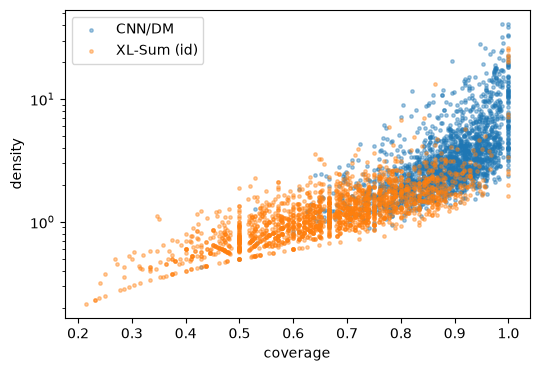

In [16]:
plt.figure(figsize=(6, 4))
plt.scatter(k_en["coverage"], k_en["density"], s=6, alpha=0.4, label="CNN/DM")
plt.scatter(k_id["coverage"], k_id["density"], s=6, alpha=0.4, label="XL-Sum (id)")
plt.xlabel("coverage")
plt.ylabel("density")
plt.yscale("log")
plt.legend()
plt.show()

Dua awannya menempati wilayah yang berbeda. XL-Sum berkumpul di kiri bawah, coverage
menengah dengan density menempel di angka 1. CNN/DailyMail bergeser ke kanan atas dan
ekornya memanjang ke atas, yaitu pasangan yang ringkasannya memang menyalin kalimat
panjang.

Yang juga penting, tidak ada kelompok yang terpisah di dalam masing masing dataset.
Keduanya satu awan tunggal, jadi median di tabel sebelumnya memang mewakili datanya dan
bukan hasil pencampuran dua kelompok berbeda.

## Diskusi

### 1. Dataset mana yang lebih extractive, dan apakah sesuai kesan awal?

**CNN/DailyMail, jelas lebih extractive, dan ketiga metrik sepakat.** Coverage 0,90
berbanding 0,68, density 2,84 berbanding 1,18, novel bigram 0,51 berbanding 0,78. Tidak
ada satu pun metrik yang memberi arah berbeda.

Sesuai dengan kesan awal di Langkah 1, dan sekarang ada ukurannya. Yang tidak terduga
dari pembacaan manual adalah seberapa dekat density XL-Sum ke angka 1. Density 1,18
berarti ringkasan XL-Sum nyaris tidak pernah menyalin frasa, cuma memakai kosakata yang
sama. Dari membaca tiga contoh saja, hal ini tidak akan terasa.

Penyebabnya bukan kebetulan. Ringkasan XL-Sum adalah paragraf pembuka artikel BBC yang
kemudian dibuang dari kolom dokumen, jadi kalimat itu memang tidak tersedia untuk
disalin. Highlight CNN/DailyMail ditulis redaksi dengan memangkas kalimat yang tetap ada
di badan artikel.

### 2. Kalau baseline lead-3 diterapkan, di dataset mana hasilnya kemungkinan lebih baik?

**Di CNN/DailyMail.** Tiga alasan, semuanya bersandar pada angka yang sudah dihitung di
notebook ini.

**Ringkasan acuannya memang tersalin dari badan artikel.** Coverage 0,90 dan density
2,84 berarti highlight CNN/DailyMail disusun dari potongan kalimat yang ada di
artikelnya. Lead-3 mengambil kalimat apa adanya, jadi dia bermain di jenis ringkasan
yang cocok. Di XL-Sum, density 1,18 berarti tidak ada frasa yang bisa diambil utuh,
sehingga kalimat apa pun yang dipilih lead-3 tidak akan bertemu dengan ringkasan
acuannya.

**Panjangnya kebetulan pas.** Dari Langkah 2, ringkasan acuan CNN/DailyMail median 4
kalimat dan 52 kata, sementara XL-Sum 1 kalimat dan 21 kata. Lead-3 otomatis mendekati
panjang yang tepat untuk CNN/DailyMail, dan kepanjangan tiga kali untuk XL-Sum. Ringkasan
yang kepanjangan menekan presisi, jadi skornya ikut turun.

**Kalimat pembuka XL-Sum sudah dibuang.** Karena paragraf pembuka diangkat jadi
ringkasan, kalimat pertama kolom `text` sebenarnya kalimat kedua artikel aslinya.
Keunggulan posisi awal yang biasa dimanfaatkan lead-3 justru sudah dipanen oleh pembuat
datasetnya. Ditambah gaya piramida terbalik berita CNN dan DailyMail yang menaruh siapa,
apa, kapan, dan di mana di paragraf pertama, lead-3 di sana memang diuntungkan.

Sebagai pembanding dari literatur, lead-3 di CNN/DailyMail dilaporkan mencapai ROUGE-1
sekitar 40 oleh See dkk. (2017), dan angka itu sulit dikalahkan model yang jauh lebih
rumit. Notebook ini tidak menghitung ROUGE karena modul tidak memintanya, jadi angka
tersebut dikutip sebagai rujukan, bukan hasil pengukuran di sini.

Implikasinya untuk pertemuan berikutnya: di CNN/DailyMail, metode extractive apa pun
wajib dibandingkan dengan lead-3 karena baseline tanpa model ini sudah tinggi. Di
XL-Sum, pendekatan extractive murni punya batas atas yang rendah karena ringkasan
acuannya tidak ada di dokumen, jadi metode abstractive lebih masuk akal.

### 3. Apa risiko memakai stemming Sastrawi untuk summarization extractive?

Risikonya bukan di kalimat yang ditampilkan, karena ringkasan extractive mengembalikan
kalimat asli dan hasil stemming cuma dipakai di balik layar. Risikonya di **skor
pemilihan kalimat yang menyesatkan**.

Over-stemming membuat dua kata yang maknanya tidak berhubungan jadi satu token, dan
kalimat yang sebenarnya tidak berkaitan jadi terlihat mirip. Contoh dari data di
Langkah 4:

| Kata asli | Hasil Sastrawi | Masalahnya |
|:-|:-|:-|
| `pemerintah` | `perintah` | kata berbeda, dan `perintah` juga sering muncul di berita |
| `pejalan` | `pejal` | `pejal` kata sah yang artinya padat atau tidak berongga |
| `pengadilan` | `adil` | institusi berubah jadi kata sifat |
| `keterangan` | `terang` | pernyataan berubah jadi kondisi cahaya |
| `perusahaan` | `usaha` | badan hukum berubah jadi upaya |

Akibat konkretnya di metode seperti TextRank atau LexRank yang membangun graf kemiripan
antar kalimat: kalimat yang menyebut `pengadilan` akan terhubung ke kalimat yang
menyebut `keadilan`, lalu nilai sentralitasnya naik tanpa alasan yang benar. Kalimat itu
lalu bisa terpilih masuk ringkasan padahal bukan kalimat penting.

Ada juga risiko kedua yang lebih praktis, yaitu kecepatan. Sastrawi cuma memproses
sekitar 39 kata baru per detik di mesin ini, jadi Latihan 4.1 yang cuma 200 dokumen
butuh beberapa menit. Modul sudah mengantisipasi ini dengan menyarankan `lru_cache`.

Kalau tetap mau memakai stemming, kompromi yang masuk akal adalah menyimpan daftar kata
yang dikecualikan untuk kata kata yang sudah diketahui bermasalah, atau memakai
lemmatizer yang lebih konservatif.

### 4. Mengapa preprocessing seperti stopword removal tidak dipakai saat menggunakan model Transformer?

Empat alasan yang saling menguatkan.

**Modelnya punya tokenizer sendiri.** BERT, BART, dan T5 memakai subword seperti
WordPiece atau SentencePiece. Kosakatanya ditentukan sejak pralatihan dan tidak bisa
diubah. Teks yang sudah distem jadi `perintah kota resmi 12 taman` akan dipecah menjadi
subword yang aneh dan menghasilkan embedding yang tidak pernah dilihat model selama
pralatihan.

**Stopword itu justru sinyal gramatikalnya.** Model Transformer memahami hubungan antar
kata lewat attention, dan kata fungsi seperti `yang`, `oleh`, `tidak`, dan `karena`
adalah penanda hubungan itu. Membuang `tidak` bisa membalik makna kalimat sepenuhnya.
Pada metode berbasis hitungan kata, kata fungsi memang cuma noise karena urutan
diabaikan. Pada Transformer, urutan dan kata fungsi adalah informasinya.

**Ketidakcocokan dengan data pralatihan.** Model dilatih pada teks alami lengkap dengan
tanda baca dan huruf kapital. Masukan yang sudah dipreprocess berat berada di luar
distribusi data latihnya, dan kinerjanya turun.

**Keluarannya harus kalimat yang bisa dibaca.** Model abstractive membangkitkan teks
baru. Kalau dilatih pada teks tanpa stopword, keluarannya juga tanpa stopword, dan
hasilnya bukan ringkasan yang bisa dibaca manusia.

Jadi preprocessing berat itu alat untuk metode berbasis hitungan kata seperti TF-IDF,
TextRank, dan LexRank. Untuk Transformer, yang pantas cuma pembersihan ringan: membuang
boilerplate, memperbaiki encoding, dan menormalkan spasi.

## Tugas Mandiri: IndoSum sebagai Dataset Ketiga

Modul meminta satu dataset summarization lain dianalisis dengan langkah yang sama,
yaitu Langkah 2 sampai Langkah 5, lalu dibandingkan dengan XL-Sum dan CNN/DailyMail.
Dataset yang dipilih **IndoSum**, benchmark summarization Bahasa Indonesia berisi
artikel berita dari portal daring beserta ringkasan yang disusun manusia.

Alasan memilih IndoSum ada dua. Pertama, dia berbahasa Indonesia sama seperti XL-Sum,
jadi kalau hasilnya berbeda jauh maka pembedanya bukan bahasa melainkan cara dataset
itu dibuat. Kedua, IndoSum dibangun sebagai benchmark untuk summarization extractive,
sehingga bisa dipakai menguji apakah metrik Grusky benar benar mampu mengenali dataset
yang memang dirancang extractive.

### Cara memuatnya

Modul sudah memperingatkan `SEACrowd/indosum` memakai loading script sehingga butuh
`trust_remote_code=True` dan versi `datasets` yang masih mendukung script. Di sini
terpasang versi 5.1.0, jadi reponya ditolak. Trik branch Parquet yang dipakai untuk
XL-Sum di Langkah 1 juga tidak bisa, karena scriptnya mengunduh dari Google Drive
sehingga Hugging Face tidak pernah mengonversinya. Pengecekan branch
`refs/convert/parquet` pada repo itu memang mengembalikan 404.

Jalan keluarnya memakai salinan IndoSum yang sudah berbentuk JSONL biasa di
`joshuasiagian/indosum`. Isinya identik, yaitu artikel pada kolom `paragraph` dan
ringkasan pada kolom `summary`, cuma sudah digabung jadi teks utuh sehingga tidak
perlu loading script sama sekali.

Berkasnya diambil dengan `hf_hub_download` lalu dibaca `pandas`, bukan lewat
`load_dataset`. Ini keputusan sadar setelah percobaan pertama gagal. Ketika panggilan
ke Hub kena batas laju permintaan tanpa token, `load_dataset` diam diam beralih ke
cache lalu melempar `ValueError: Couldn't find cache for joshuasiagian/indosum`, karena
hash konfigurasinya tidak cocok dengan yang tersimpan. Mengunduh satu berkas JSONL
langsung membuang seluruh lapisan itu, dan berkasnya ikut tersimpan di cache sehingga
sel ini tetap jalan tanpa internet.

Yang dipakai fold pertama split validasi. Isinya 749 artikel, lebih sedikit daripada
2.000 sampel di praktikum, karena memang segitu ukuran split validasi IndoSum. Seluruh
isinya dipakai tanpa pengambilan sampel acak.

In [17]:
from huggingface_hub import hf_hub_download

# Berkasnya diunduh langsung, bukan lewat load_dataset, supaya tidak bergantung pada
# mesin cache datasets yang sempat gagal ketika panggilan ke Hub kena batas laju.
berkas_indosum = hf_hub_download("joshuasiagian/indosum", "data/dev.01.jsonl",
                                 repo_type="dataset")
df_in = (pd.read_json(berkas_indosum, lines=True)
           .rename(columns={"paragraph": "text"})[["text", "summary"]])

print(f"IndoSum (id): {df_in.shape[0]} baris, kolom {list(df_in.columns)}\n")
print("Contoh pasangan pertama")
print("RINGKASAN:", df_in.loc[0, "summary"][:240])
print("DOKUMEN  :", df_in.loc[0, "text"][:240], "...")

IndoSum (id): 749 baris, kolom ['text', 'summary']

Contoh pasangan pertama
RINGKASAN: Marc Marquez menjadi yang tercepat pada sesi FP1 GP San Marino di Sirkuit Misano, Jumat (8 / 9 / 2017). Pada sesi ini, Marquez menorehkan putaran tercepat 1 menit 33,556 detik. Ia mengungguli dua pebalap Ducati Team, Michele Pirro dan Andre
DOKUMEN  : JUARA.NET, MISANO ADRIATICO - Pebalap Repsol Honda Team, Marc Marquez, berhasil menjadi yang tercepat pada sesi latihan bebas pertama (FP1) GP San Marino di Sirkuit Misano, Jumat (8 / 9 / 2017). Pada sesi ini, Marquez menorehkan putaran ter ...


Dibaca sekilas saja sudah terasa ringkasan IndoSum ini banyak menyalin. Kalimat
pembuka ringkasannya hampir sama persis dengan kalimat di dalam artikel, cuma dipotong
bagian depannya. Dugaan itu diukur di bawah.

Satu catatan jujur soal datanya. Teks IndoSum aslinya tersimpan sebagai token, dan
salinan JSONL ini menggabungkannya kembali dengan spasi. Akibatnya ada artefak kecil
seperti tanggal yang tertulis `8 / 9 / 2017` dan sesekali spasi sebelum titik. Untuk
perhitungan di sini pengaruhnya bisa diabaikan, karena `tok` memakai `\w+` yang memang
membuang tanda baca.

### Langkah 2 untuk IndoSum: panjang dan rasio kompresi

Fungsi `profil` dari Langkah 2 dipakai ulang apa adanya, lalu hasilnya disandingkan
dengan dua dataset praktikum.

In [18]:
# Fungsi profil dari Langkah 2 dipakai ulang apa adanya untuk dataset ketiga
p_in = profil(df_in)

# Tiga dataset disandingkan dalam satu tabel median
tabel_panjang3 = pd.concat({
    "IndoSum (id)": p_in.median(),
    "XL-Sum (id)": p_id.median(),
    "CNN/DM (en)": p_en.median(),
}, axis=1).round(1)
tabel_panjang3.index.name = "median"
display(tabel_panjang3)

print(f"Jumlah pasangan: IndoSum {len(df_in)}, XL-Sum {len(df_id)}, CNN/DM {len(df_en)}")

,IndoSum (id),XL-Sum (id),CNN/DM (en)
median,,,
kata_dok,276.0,257.0,610.5
kata_ringkasan,60.0,21.0,52.0
kalimat_dok,16.0,14.0,28.0
kalimat_ringkasan,4.0,1.0,4.0
kompresi,4.7,12.5,11.2


Jumlah pasangan: IndoSum 749, XL-Sum 2000, CNN/DM 2000


### Membaca tabel panjang

Panjang dokumen IndoSum 276 kata, mirip XL-Sum yang 257 kata, dan keduanya jauh lebih
pendek daripada CNN/DailyMail yang 610,5 kata. Wajar, karena IndoSum dan XL-Sum sama
sama berita daring berbahasa Indonesia.

Yang membedakan justru panjang ringkasannya. Ringkasan IndoSum 60 kata dan 4 kalimat,
hampir tiga kali ringkasan XL-Sum yang 21 kata dan 1 kalimat. Akibatnya rasio kompresi
IndoSum cuma **4,7**, jauh di bawah XL-Sum 12,5 dan CNN/DailyMail 11,2.

Rasio 4,7 artinya model cukup membuang sekitar 79 persen isi dokumen, sementara di dua
dataset lain harus membuang sekitar 92 persen. Dari sisi ini saja IndoSum sudah
terlihat sebagai tugas yang paling ringan di antara ketiganya.

### Langkah 5 untuk IndoSum: coverage, density, dan novel n-gram

Fungsi `karakter` dari Langkah 5 juga dipakai ulang tanpa perubahan.

In [19]:
# Fungsi karakter dari Langkah 5 juga dipakai ulang tanpa perubahan
k_in = karakter(df_in)

tabel_karakter3 = pd.concat({
    "IndoSum (id)": k_in.median(),
    "XL-Sum (id)": k_id.median(),
    "CNN/DM (en)": k_en.median(),
}, axis=1).round(2)
tabel_karakter3.index.name = "median"
display(tabel_karakter3)

# Angka pendukung: berapa pasangan yang coverage-nya hampir sempurna
for nama, k in [("IndoSum (id)", k_in), ("XL-Sum (id)", k_id), ("CNN/DM (en)", k_en)]:
    n = len(k)
    print(f"{nama}: coverage >= 0,95 pada {int((k['coverage'] >= 0.95).sum()):4d} dari {n:4d} "
          f"pasangan ({(k['coverage'] >= 0.95).mean() * 100:5.1f} persen), "
          f"density {k['density'].min():.2f} sampai {k['density'].max():.1f}")

,IndoSum (id),XL-Sum (id),CNN/DM (en)
median,,,
coverage,1.00,0.68,0.90
density,25.02,1.18,2.84
novel_bigram,0.05,0.78,0.51


IndoSum (id): coverage >= 0,95 pada  637 dari  749 pasangan ( 85.0 persen), density 0.67 sampai 76.0
XL-Sum (id): coverage >= 0,95 pada   23 dari 2000 pasangan (  1.1 persen), density 0.21 sampai 26.0
CNN/DM (en): coverage >= 0,95 pada  417 dari 2000 pasangan ( 20.8 persen), density 0.43 sampai 41.0


### Membaca tabel karakter

Angkanya ekstrem dan tidak ambigu sama sekali.

| Metrik (median) | IndoSum (id) | XL-Sum (id) | CNN/DM (en) |
|:-|-:|-:|-:|
| coverage | 1,00 | 0,68 | 0,90 |
| density | 25,02 | 1,18 | 2,84 |
| novel bigram | 0,05 | 0,78 | 0,51 |

Coverage IndoSum **1,00**, dan itu nilai median, bukan nilai maksimum. Artinya pada
lebih dari separuh pasangan, setiap kata di ringkasan memang ada di dokumen. Density
**25,02** berarti fragmen salinannya panjang panjang, sekitar 25 kata sekaligus, atau
kira kira satu kalimat utuh. Novel bigram **0,05** berarti cuma 5 persen pasangan kata
di ringkasan yang tidak ditemukan di artikel, dan angka sekecil itu konsisten dengan
nilai dasar yang muncul dari titik sambungan antar kalimat seperti yang dibahas di
Langkah 5.

Kesimpulan teknisnya, **ringkasan acuan IndoSum pada dasarnya adalah kalimat kalimat
yang disalin utuh dari artikelnya.** Ini bukan kelemahan datasetnya, melainkan memang
rancangannya: IndoSum dibangun sebagai benchmark extractive, dengan anotator memilih
kalimat mana dari artikel yang masuk ringkasan.

Bandingkan dengan dua dataset praktikum. CNN/DailyMail yang di praktikum tadi terlihat
paling extractive dengan density 2,84, ternyata cuma sepersepuluh density IndoSum.
Jadi skala "extractive" itu jauh lebih lebar daripada yang terlihat kalau cuma
membandingkan dua dataset.

### Visualisasi perbandingan tiga dataset

Dua panel. Panel kiri memetakan coverage terhadap density seperti gaya Grusky dkk.,
dan panel kanan merangkum sebaran density tiap dataset dalam boxplot. Keduanya memakai
sumbu density berskala log, karena rentangnya sangat lebar, dari 0,67 sampai 76,0.

Boxplot ditambahkan karena scatter saja sulit dibaca ketika titiknya menumpuk. Boxplot
memperlihatkan median dan rentang antar kuartil secara langsung, jadi klaim bahwa
ketiganya menempati wilayah berbeda bisa diperiksa, bukan cuma dipercaya.

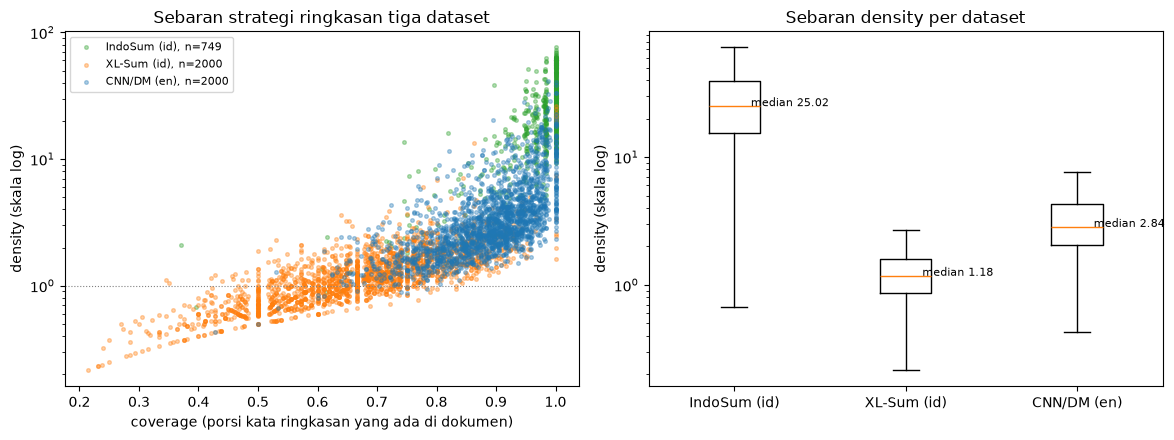

In [20]:
warna = {"IndoSum (id)": "tab:green", "XL-Sum (id)": "tab:orange", "CNN/DM (en)": "tab:blue"}
kumpulan = [("IndoSum (id)", k_in), ("XL-Sum (id)", k_id), ("CNN/DM (en)", k_en)]

# Panel kiri sebaran gaya Grusky, panel kanan boxplot supaya median terbaca jelas
fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(12, 4.5))

for nama, k in kumpulan:
    kiri.scatter(k["coverage"], k["density"], s=7, alpha=0.35,
                 color=warna[nama], label=f"{nama}, n={len(k)}")
kiri.axhline(1.0, color="gray", linewidth=0.8, linestyle=":")
kiri.set_xlabel("coverage (porsi kata ringkasan yang ada di dokumen)")
kiri.set_ylabel("density (skala log)")
kiri.set_yscale("log")
kiri.set_title("Sebaran strategi ringkasan tiga dataset")
kiri.legend(loc="upper left", fontsize=8)

# matplotlib 3.11 memakai tick_labels, argumen labels sudah dihapus
kanan.boxplot([k["density"] for _, k in kumpulan],
              tick_labels=[nama for nama, _ in kumpulan], showfliers=False)
kanan.set_yscale("log")
kanan.set_ylabel("density (skala log)")
kanan.set_title("Sebaran density per dataset")
for i, (nama, k) in enumerate(kumpulan, start=1):
    kanan.annotate(f"median {k['density'].median():.2f}", (i, k["density"].median()),
                   textcoords="offset points", xytext=(12, 0), fontsize=8)

plt.tight_layout()
plt.show()

Panel kiri memperlihatkan tiga awan yang nyaris tidak bertumpang tindih. IndoSum
menempel di dinding kanan pada coverage 1,0 dan melayang tinggi di sumbu density.
CNN/DailyMail di tengah, dan XL-Sum berkumpul di kiri bawah menempel garis density 1.

Panel kanan menguatkannya dengan angka. Kotak IndoSum berada jauh di atas kotak
CNN/DailyMail, dan keduanya tidak beririsan sama sekali dengan kotak XL-Sum. Jadi
pemisahan ketiga dataset ini bukan efek beberapa pencilan, melainkan berlaku untuk
sebagian besar datanya.

### Interpretasi dan implikasi pemilihan metode

**Bahasa bukan penentu karakter dataset.** IndoSum dan XL-Sum sama sama berbahasa
Indonesia dan sama sama berita, dengan panjang dokumen yang mirip, 276 berbanding 257
kata. Tapi density keduanya 25,02 berbanding 1,18, terpaut lebih dari dua puluh kali.
Yang menentukan ternyata cara ringkasan acuannya dibuat. IndoSum memakai anotator yang
memilih kalimat dari artikel, sedangkan ringkasan XL-Sum adalah paragraf pembuka BBC
yang justru dibuang dari kolom dokumen.

**Implikasinya pada pemilihan metode berbeda untuk tiap dataset.**

- Untuk **IndoSum**, metode extractive seperti TextRank, LexRank, atau bahkan lead-3
  masuk akal dan batas atasnya tinggi, karena jawaban yang benar memang ada di dalam
  dokumen dalam bentuk kalimat utuh. Memakai model abstractive di sini justru membuang
  tenaga dan menambah risiko halusinasi, padahal tugasnya sebenarnya memilih kalimat.
- Untuk **CNN/DailyMail**, extractive masih kompetitif tapi tidak cukup sendirian,
  karena density 2,84 menunjukkan ringkasannya memangkas dan merangkai ulang kalimat,
  bukan menyalin utuh.
- Untuk **XL-Sum**, extractive murni punya batas atas yang rendah dan pendekatan
  abstractive lebih tepat, karena kalimat ringkasannya secara definisi tidak tersedia
  di dokumen.

**Catatan soal evaluasi.** Rasio kompresi IndoSum yang cuma 4,7 berarti ringkasan
acuannya panjang, sekitar 4 kalimat. Baseline lead-3 di dataset seperti ini
kemungkinan besar sudah sangat kuat, jadi setiap metode baru wajib dibandingkan dengan
lead-3 sebelum diklaim berhasil. Tanpa pembanding itu, skor ROUGE yang terlihat tinggi
bisa saja cuma efek dari dataset yang memang mudah.

**Keterbatasan.** Sampel IndoSum di sini 749 artikel, lebih kecil daripada 2.000 untuk
dua dataset lain, karena memang segitu ukuran fold validasinya. Median dari 749 sampel
sudah cukup stabil, tapi perbandingan jumlah pencilan antar dataset sebaiknya dibaca
dengan hati hati. Selain itu teks IndoSum hasil penggabungan token, sehingga ejaan
tanda bacanya tidak seasli dua dataset lain.

## Kesimpulan

**Rasio kompresi tidak cukup untuk mengenali karakter dataset summarization.** XL-Sum
dan CNN/DailyMail punya rasio yang nyaris sama, 12,5 dan 11,2, tapi strategi
ringkasannya berbeda jauh. Yang membedakan coverage, density, dan novel n-gram.

**Tiga dataset menempati tiga posisi yang jelas terpisah.** Diurutkan dari paling
extractive: IndoSum dengan coverage 1,00 dan density 25,02, CNN/DailyMail dengan 0,90
dan 2,84, lalu XL-Sum dengan 0,68 dan 1,18. Novel bigramnya bergerak berlawanan arah,
0,05 lalu 0,51 lalu 0,78, persis seperti yang diharapkan.

**Yang menentukan karakter dataset bukan bahasanya, tapi cara ringkasan acuannya
dibuat.** IndoSum dan XL-Sum sama sama berita berbahasa Indonesia dengan panjang
dokumen mirip, 276 berbanding 257 kata, tapi densitynya terpaut lebih dari dua puluh
kali. IndoSum memakai anotator yang memilih kalimat dari artikel, sedangkan ringkasan
XL-Sum adalah paragraf pembuka BBC yang dibuang dari kolom dokumen.

**Pilihan metode mengikuti temuan itu.** Di IndoSum metode extractive punya batas atas
yang tinggi karena jawabannya memang ada sebagai kalimat utuh di dokumen. Di
CNN/DailyMail extractive masih kompetitif tapi perlu pemangkasan. Di XL-Sum extractive
murni punya batas atas rendah sehingga arahnya ke abstractive. Pada ketiganya,
baseline lead-3 wajib jadi pembanding sebelum metode baru diklaim berhasil.

**Segmentasi kalimat bukan langkah sepele untuk Bahasa Indonesia.** Pemotongan naif
memberi 13 potongan untuk teks 4 kalimat, NLTK bawaan memberi 7, dan baru setelah
daftar singkatan dan penyamaran URL ditambahkan hasilnya benar 4. Pencarian berbasis
data di 2.000 artikel menemukan `Jr.` dan `St.` yang terlewat dari daftar awal.

**Preprocessing harus dipilih sesuai metode, bukan dipakai karena kebiasaan.** Pada
200 dokumen XL-Sum, stopword removal cuma mengecilkan kosakata 1,4 persen sementara
stemming mengecilkan 31,5 persen. Tapi stemming Sastrawi juga menggabungkan
`pengadilan` dengan `adil` dan `keterangan` dengan `terang`, yang bisa menyesatkan
skor kemiripan kalimat. Untuk model Transformer, preprocessing berat seperti ini
justru merusak.

## Catatan pemuatan dataset

Dua dari tiga dataset tidak bisa dimuat dengan perintah `load_dataset` yang biasa,
dan keduanya karena sebab yang sama, yaitu reponya masih memakai loading script
sedangkan `datasets` versi 3 ke atas sudah membuang dukungan script.

| Dataset | Kendala | Jalan keluar |
|:-|:-|:-|
| XL-Sum Indonesia | repo memakai loading script | branch `refs/convert/parquet` dengan `data_dir="indonesian"` |
| CNN/DailyMail | tidak ada | `load_dataset` biasa |
| IndoSum | loading script, dan tidak punya branch Parquet karena datanya diunduh dari Google Drive | salinan JSONL di `joshuasiagian/indosum` |

Pola ini layak diingat. Kalau sebuah dataset ditolak karena loading script, periksa
dulu branch `refs/convert/parquet`. Kalau branch itu tidak ada, berarti datanya
diunduh dari luar Hugging Face, dan harus dicari salinan yang sudah berbentuk Parquet,
CSV, atau JSONL.

## Referensi

1. Grusky, M., Naaman, M., & Artzi, Y. (2018). *Newsroom: A Dataset of 1.3 Million
   Summaries with Diverse Extractive Strategies.* NAACL. Sumber definisi coverage,
   density, dan algoritma fragmen extractive.
2. Hasan, T. dkk. (2021). *XL-Sum: Large-Scale Multilingual Abstractive Summarization
   for 44 Languages.* Findings of ACL. Dataset XL-Sum.
3. Kurniawan, K. & Louvan, S. (2018). *IndoSum: A New Benchmark Dataset for Indonesian
   Text Summarization.* IALP. Dataset IndoSum yang dipakai di tugas mandiri.
4. See, A., Liu, P. J., & Manning, C. D. (2017). *Get To The Point: Summarization with
   Pointer-Generator Networks.* ACL. Sumber angka baseline lead-3 pada CNN/DailyMail.
5. Kiss, T. & Strunk, J. (2006). *Unsupervised Multilingual Sentence Boundary
   Detection.* Computational Linguistics. Algoritma Punkt di balik `sent_tokenize`.